# DxForge — 01 · Dataset Understanding, Preprocessing & EDA

**Rubric coverage:** Dataset Understanding, Preprocessing & EDA (15) · Feature Engineering, Selection & Dimensionality Reduction (8)

DxForge uses three datasets, one per ML task:

| Dataset | Task | Rows (full mode) | Label source |
|---|---|---|---|
| Intents | NL intent → UDS service (13 classes) | ~3.9k after cleaning | template + deterministic engine |
| Outcomes | request + context → POSITIVE / NRC | 8,000 (4 ECU profiles) | deterministic engine |
| Traces | ECU response log → defect / normal | 3,000 golden + 1,000 test | injected defects |

> **Synthetic data disclosure.** No licence-clean public corpus of UDS diagnostic intents exists, and real OEM ECU traces are proprietary.
> All rows are generated by `dxforge/ml/dataset.py` (seeded, reproducible) and labelled by the deterministic protocol engine. This notebook
> measures how realistic and how difficult that data is, rather than assuming it.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split

from dxforge.kb import load_kb
from dxforge.ml import SEED
from dxforge.ml.dataset import (generate_intents, clean_intents, group_split, generate_outcomes,
                                generate_traces, BASE_LATENCY_MS, P2_SERVER_MS)
from dxforge.ml.features import text_features, domain_tabular
from dxforge.ml.intent_model import embedding_2d

pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.figsize": (10, 4.5), "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
kb = load_kb()
print("Seed:", SEED)

Seed: 42


## 1. Intent dataset — raw data and quality audit
The raw export deliberately contains the defects a real tester-log export has (empty rows, stray whitespace, duplicates), so cleaning is measured, not assumed.

In [2]:
raw = generate_intents(kb, scale=1.0, seed=SEED)
print(f"Raw intent rows: {len(raw):,}  |  classes: {raw.label.nunique()}")
schema = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "unique": raw.nunique(),
})
schema

Raw intent rows: 4,542  |  classes: 13


,dtype,missing,missing_%,unique
text,str,34,0.75,3891
label,str,0,0.00,13
template_id,str,0,0.00,135
session,str,0,0.00,3
unlocked,bool,0,0.00,2
noise_typo,int64,0,0.00,2
noise_abbrev,int64,0,0.00,2
noise_filler,int64,0,0.00,2
noise_case,int64,0,0.00,2
sid,float64,406,8.94,11


In [3]:
text = raw["text"]
audit = pd.Series({
    "null text": int(text.isna().sum()),
    "blank / whitespace-only text": int((text.fillna("x").str.strip() == "").sum()),
    "leading/trailing or double spaces": int(text.dropna().str.contains(r"^\s|\s$|\s{2,}").sum()),
    "exact duplicate rows": int(raw.duplicated().sum()),
    "duplicate text (any label/context)": int(raw.duplicated(subset=["text"]).sum()),
}, name="rows")
print("Note: nulls in sid / request_hex / nrc are *structural*: refusal classes have no request,")
print("and nrc is only defined for negative outcomes. They are not imputed.")
audit.to_frame()

Note: nulls in sid / request_hex / nrc are *structural*: refusal classes have no request,
and nrc is only defined for negative outcomes. They are not imputed.


,rows
null text,34
blank / whitespace-only text,35
leading/trailing or double spaces,166
exact duplicate rows,262
duplicate text (any label/context),650


## 2. Cleaning pipeline
`clean_intents` → strip → drop empty → collapse whitespace → de-duplicate → `normalize()` (lower-case, hex identifiers → `hexid`, punctuation removal, domain abbreviation expansion).
The same `normalize()` runs at inference time, so there is no train/serve skew.

In [4]:
clean_df, report = clean_intents(raw)
print("Cleaning report:", report)
examples = clean_df[clean_df["text"].str.contains(r"0x|\$|\b(diag|sw|ext|sec|pls)\b", case=False, regex=True)]
examples.sample(10, random_state=SEED)[["text", "text_clean", "label"]]

Cleaning report: {'rows_in': 4542, 'dropped_empty': 69, 'dropped_duplicates': 288, 'rows_out': 4185}


,text,text_clean,label
1605,abort the routdne 0xff00 routine,abort the routdne hexid routine,RoutineControl
2766,pls send key to unlock the ecu for this ecu,please send key to unlock the ecu for this ecu,SecurityAccess
177,set lock state of the doors = 0x01,set lock state of the doors hexid,WriteDataByIdentifier
3719,can you show me the DID 0xF187?,can you show me the did hexid,ReadDataByIdentifier
1435,now write the identifier $7777 to unlocked please,now write the identifier hexid to unlocked please,WriteDataByIdentifier
304,show me the sw ver vlue,show me the software version vlue,ReadDataByIdentifier
1066,PLS LOOK UP THE 4102?,please look up the hexid,ReadDataByIdentifier
822,can you bypass sec access?,can you bypass security access,UnsafeRequest
3448,output the current identifier 0xf1a0,output the current identifier hexid,ReadDataByIdentifier
3976,i need to get the 0x4200 from the controller,i need to get the hexid from the controller,ReadDataByIdentifier


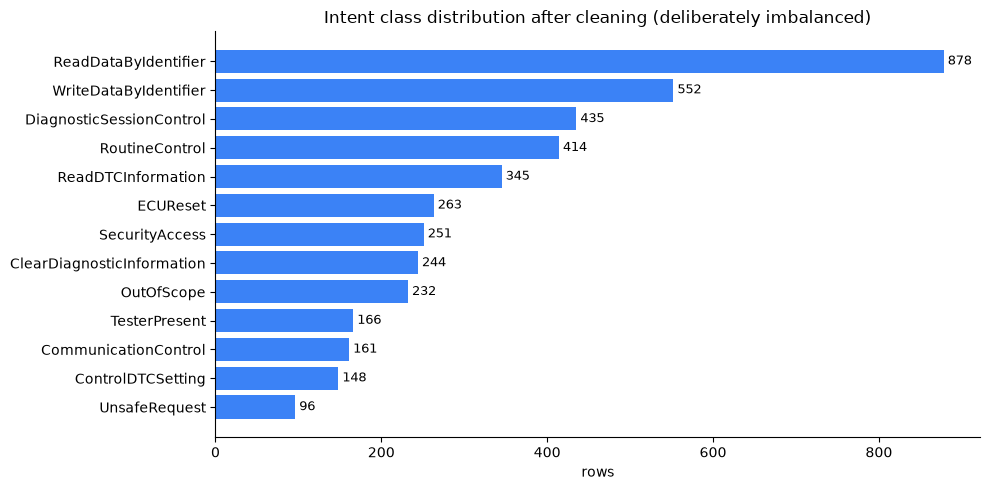

Imbalance ratio (max/min): 9.1x  ->  handled with class_weight='balanced' + macro-F1


In [5]:
counts = clean_df["label"].value_counts()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(counts.index[::-1], counts.values[::-1], color="#3b82f6")
for i, v in enumerate(counts.values[::-1]):
    ax.text(v + 5, i, str(v), va="center", fontsize=9)
ax.set_title("Intent class distribution after cleaning (deliberately imbalanced)")
ax.set_xlabel("rows")
plt.tight_layout(); plt.show()
print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.1f}x  ->  handled with class_weight='balanced' + macro-F1")

## 3. Noise profile
Each row records which noise was injected. This shows how much of the data a pure keyword matcher will mis-handle (typos and abbreviations break exact keyword matches).

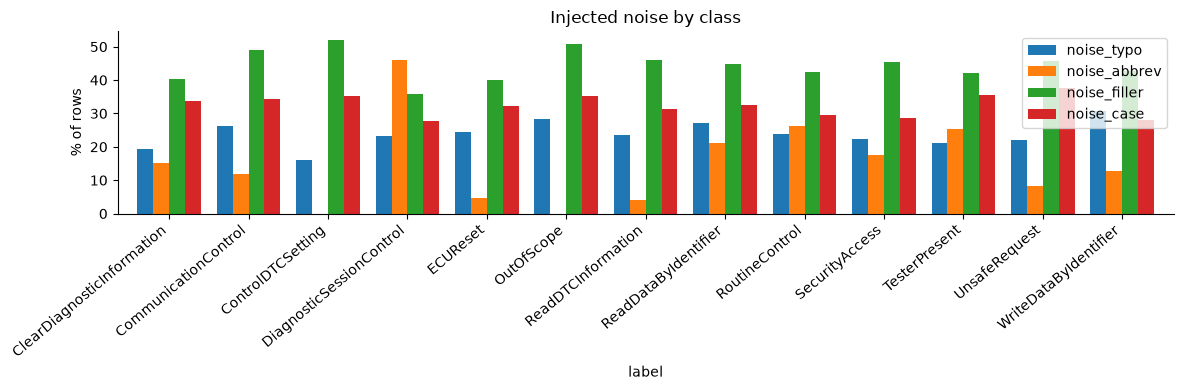

,noise_typo,noise_abbrev,noise_filler,noise_case
label,,,,
ALL,24.9,17.7,43.6,31.4


In [6]:
noise_cols = ["noise_typo", "noise_abbrev", "noise_filler", "noise_case"]
noise = clean_df.groupby("label")[noise_cols].mean().mul(100).round(1)
noise.loc["ALL"] = clean_df[noise_cols].mean().mul(100).round(1)
ax = noise.drop("ALL").plot(kind="bar", figsize=(12, 4), width=0.8)
ax.set_ylabel("% of rows"); ax.set_title("Injected noise by class")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()
noise.tail(1)

## 4. Text length distributions and outliers

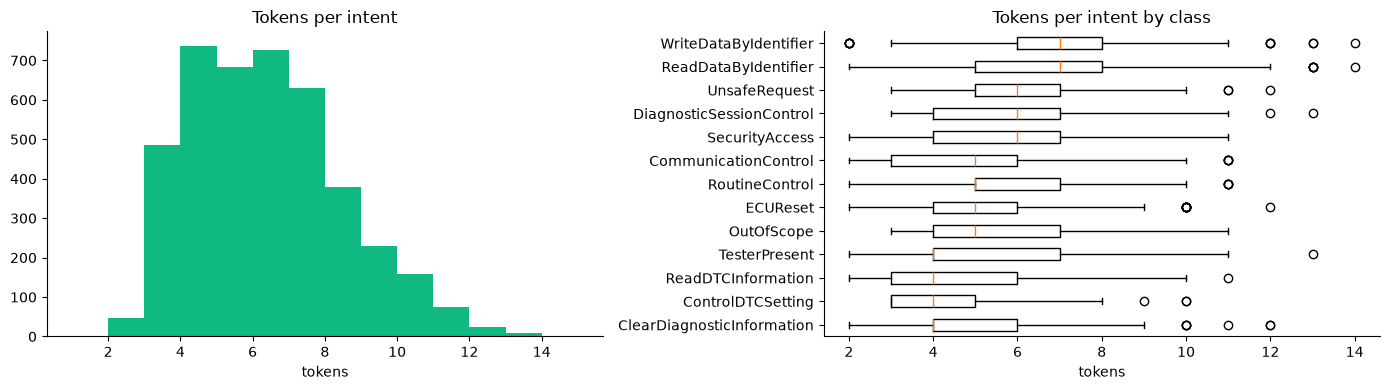

IQR rule: tokens > 11.5 flagged as length outliers: 33 rows (0.8%)
They are long-but-valid requests (filler words), so they are kept, not dropped.


,text,label
81,now fetch the data id 0xf18c from the module on the bench,ReadDataByIdentifier
615,i need to read the valeu of door lock sttatus for this ecu,ReadDataByIdentifier
962,i need to write data identifier cal set to locked on the...,WriteDataByIdentifier
1205,could you store 0x01 to the dome light brightness for th...,WriteDataByIdentifier
1310,Can you ping the ecu to keep the session open on the bcm,TesterPresent


In [7]:
clean_df["tokens"] = clean_df["text_clean"].str.split().str.len()
clean_df["chars"] = clean_df["text_clean"].str.len()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
a1.hist(clean_df["tokens"], bins=range(1, clean_df["tokens"].max() + 2), color="#10b981")
a1.set_title("Tokens per intent"); a1.set_xlabel("tokens")
order = clean_df.groupby("label")["tokens"].median().sort_values().index
a2.boxplot([clean_df.loc[clean_df.label == l, "tokens"] for l in order], vert=False, tick_labels=order)
a2.set_title("Tokens per intent by class"); a2.set_xlabel("tokens")
plt.tight_layout(); plt.show()

q1, q3 = clean_df["tokens"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
outl = clean_df[clean_df["tokens"] > upper]
print(f"IQR rule: tokens > {upper:.1f} flagged as length outliers: {len(outl)} rows ({len(outl)/len(clean_df):.1%})")
print("They are long-but-valid requests (filler words), so they are kept, not dropped.")
outl[["text", "label"]].head(5)

## 5. Vocabulary: most frequent tokens per class

In [8]:
stop = {"the", "a", "to", "of", "for", "me", "please", "on", "can", "you", "i", "it", "now", "from", "in", "with", "into", "an"}
top = {}
for label, g in clean_df.groupby("label"):
    toks = pd.Series(" ".join(g["text_clean"]).split())
    top[label] = ", ".join(toks[~toks.isin(stop)].value_counts().head(6).index)
pd.Series(top, name="top tokens").to_frame()

,top tokens
ClearDiagnosticInformation,"fault, clear, codes, memory, all, dtc"
CommunicationControl,"normal, tx, communication, rx, and, messages"
ControlDTCSetting,"dtc, setting, logging, off, storage, detection"
DiagnosticSessionControl,"session, diagnostic, extended, put, ecu, mode"
ECUReset,"reset, ecu, restart, key, off, reboot"
OutOfScope,"is, this, what, my, play, music"
ReadDTCInformation,"dtc, codes, faults, read, list, fault"
ReadDataByIdentifier,"hexid, data, number, identifier, read, need"
RoutineControl,"routine, hexid, erase, check, results, self"
SecurityAccess,"security, access, key, seed, ecu, level"


## 6. Leakage analysis — why the split must be grouped by template
Paraphrases of one sentence frame are near-duplicates. A random row split puts them on both sides, so the test set is effectively seen in training.
We measure that directly: the share of test rows whose **cleaned text appears verbatim in train**.

In [9]:
tr_r, te_r = train_test_split(clean_df, test_size=0.2, random_state=SEED, stratify=clean_df["label"])
rand_leak = te_r["text_clean"].isin(set(tr_r["text_clean"])).mean()
tr_g, te_g = group_split(clean_df)
group_leak = te_g["text_clean"].isin(set(tr_g["text_clean"])).mean()
frames = clean_df.groupby("label")["template_id"].nunique()
print(f"Paraphrase frames (groups): {clean_df.template_id.nunique()}  ({frames.min()}-{frames.max()} per class)")
print(f"Random split : {rand_leak:.1%} of test rows appear verbatim in train  -> inflated scores")
print(f"Grouped split: {group_leak:.1%} of test rows appear verbatim in train  -> honest scores")
print("=> All intent CV uses StratifiedGroupKFold(groups=template_id).")

Paraphrase frames (groups): 135  (9-14 per class)
Random split : 26.2% of test rows appear verbatim in train  -> inflated scores
Grouped split: 0.0% of test rows appear verbatim in train  -> honest scores
=> All intent CV uses StratifiedGroupKFold(groups=template_id).


## 7. Text feature engineering and dimensionality reduction
* word TF-IDF 1–2 grams (sublinear TF) — verbs and objects (“read vin”, “clear dtc”)
* char_wb TF-IDF 2–4 grams — robustness to typos (“ennable”) and abbreviations
* hex identifiers collapsed to one `hexid` token — the service depends on *whether* an identifier is present, not on its value

In [10]:
word_only = text_features(word_ngrams=(1, 2), use_char=False).fit(clean_df["text_clean"])
union = text_features(word_ngrams=(1, 2), char_ngrams=(2, 4)).fit(clean_df["text_clean"])
X = union.transform(clean_df["text_clean"])
n_word = len(word_only.vocabulary_)
print(f"Word features: {n_word:,}   word+char features: {X.shape[1]:,}")
print(f"Matrix: {X.shape[0]:,} x {X.shape[1]:,}, density {X.nnz / (X.shape[0] * X.shape[1]):.3%}  (sparse -> linear models suit it)")

Word features: 1,951   word+char features: 5,035
Matrix: 4,185 x 5,035, density 1.727%  (sparse -> linear models suit it)


{'svd50_explained_variance': 0.434, 'pca2_explained_variance': 0.104, 'kmeans_ari': 0.234, 'kmeans_nmi': 0.506}


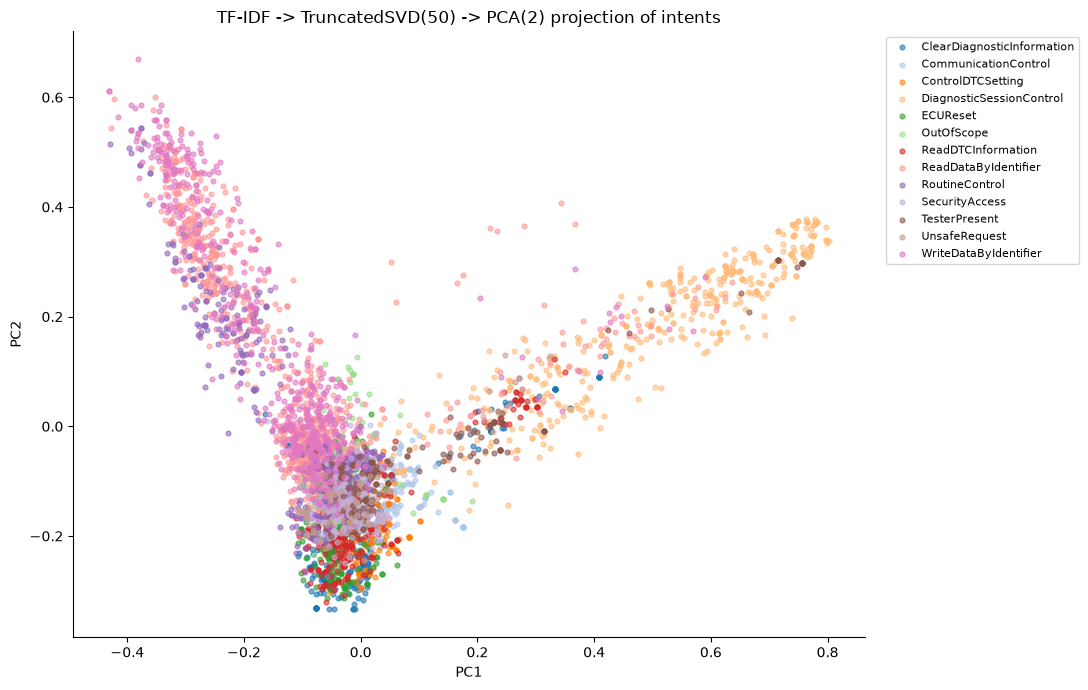

2 components keep only a small share of variance: the classes separate in higher dimensions,
which the SVD-components curve in notebook 02 quantifies.


In [11]:
emb, stats = embedding_2d(clean_df, text_features(word_ngrams=(1, 2), char_ngrams=(2, 4)))
print({k: round(v, 3) for k, v in stats.items()})
fig, ax = plt.subplots(figsize=(11, 7))
cmap = matplotlib.colormaps["tab20"]
for i, label in enumerate(sorted(emb["label"].unique())):
    m = emb["label"] == label
    ax.scatter(emb.loc[m, "pc1"], emb.loc[m, "pc2"], s=12, alpha=0.6, color=cmap(i), label=label)
ax.set_title("TF-IDF -> TruncatedSVD(50) -> PCA(2) projection of intents")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()
print("2 components keep only a small share of variance: the classes separate in higher dimensions,")
print("which the SVD-components curve in notebook 02 quantifies.")

## 8. Outcome dataset (tabular)
Structured requests × session × security state × 4 ECU profiles, labelled by the engine. `DCU-DEMO` is held out entirely to test generalisation to an unseen ECU.

In [12]:
outcome_df = generate_outcomes(n_per_profile=2000, seed=SEED)
print(f"{len(outcome_df):,} rows, {outcome_df.label.nunique()} classes")
pd.crosstab(outcome_df["ecu_id"], outcome_df["label"], margins=True)

8,000 rows, 7 classes


label,NRC_11,NRC_12,NRC_13,NRC_31,NRC_33,NRC_7F,POSITIVE,All
ecu_id,,,,,,,,
BCM-DEMO,111,146,93,182,16,329,1123,2000
DCU-DEMO,448,129,67,317,0,128,911,2000
GW-DEMO,443,118,87,94,0,205,1053,2000
PCM-DEMO,298,145,70,261,9,239,978,2000
All,1300,538,317,854,25,901,4065,8000


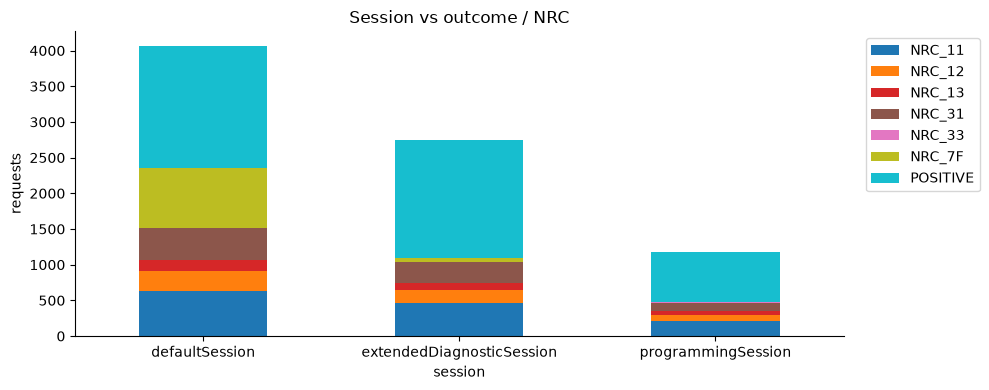

NRC_33 (securityAccessDenied) is rare -> reported with macro-F1, not accuracy.


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
pd.crosstab(outcome_df["session"], outcome_df["label"]).plot(kind="bar", stacked=True, ax=ax, colormap="tab10")
ax.set_title("Session vs outcome / NRC"); ax.set_ylabel("requests")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
print("NRC_33 (securityAccessDenied) is rare -> reported with macro-F1, not accuracy.")

### Engineered domain features: correlation and relevance
Raw identifiers (SID, DID, …) are joined against the KB and the ECU support matrix to give features such as `did_writable`, `session_deficit`, and `locked_and_needs_security`.
Redundant features (`session_*` one-hots vs `session_rank`, `sid_value`) are kept on purpose to show that selection removes them.

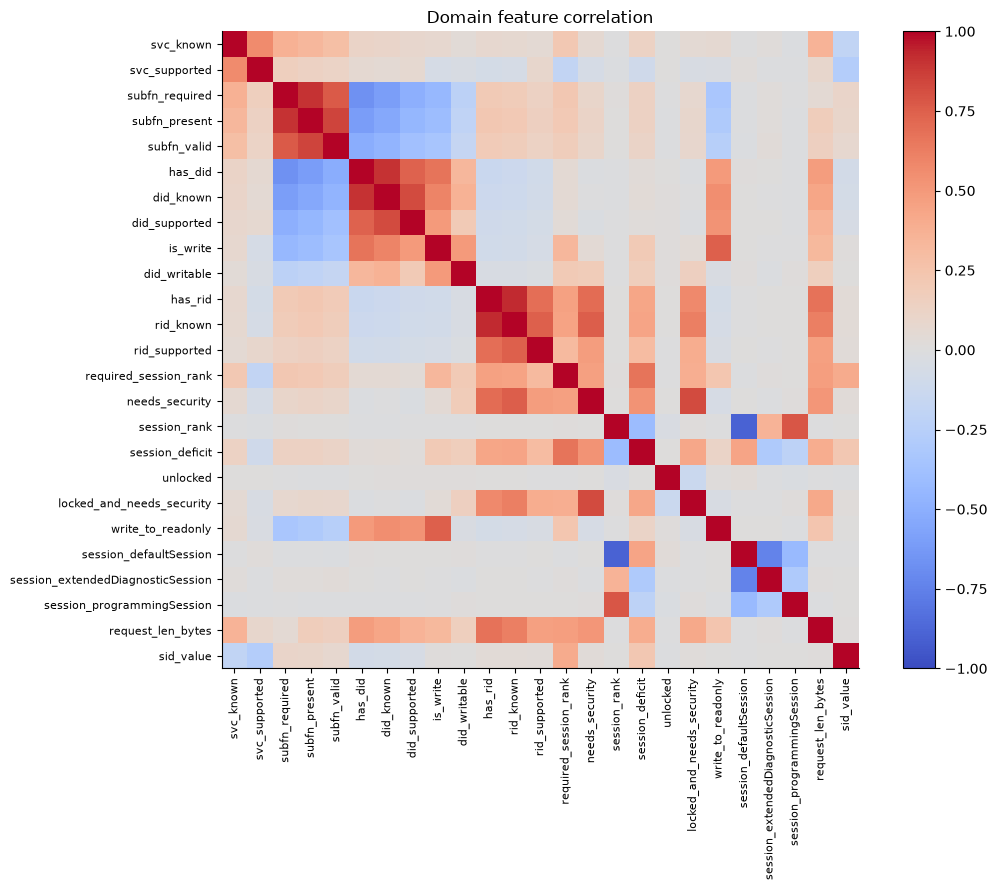

Most correlated (redundant) pairs:
has_rid         rid_known                    0.927
subfn_required  subfn_present                0.906
has_did         did_known                    0.901
session_rank    session_defaultSession       0.896
subfn_present   subfn_valid                  0.851
needs_security  locked_and_needs_security    0.824
dtype: float64


In [14]:
F = domain_tabular(outcome_df)
corr = F.corr().fillna(0)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
fig.colorbar(im, fraction=0.046); ax.set_title("Domain feature correlation")
plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Most correlated (redundant) pairs:"); print(pairs.abs().sort_values(ascending=False).head(6).round(3))

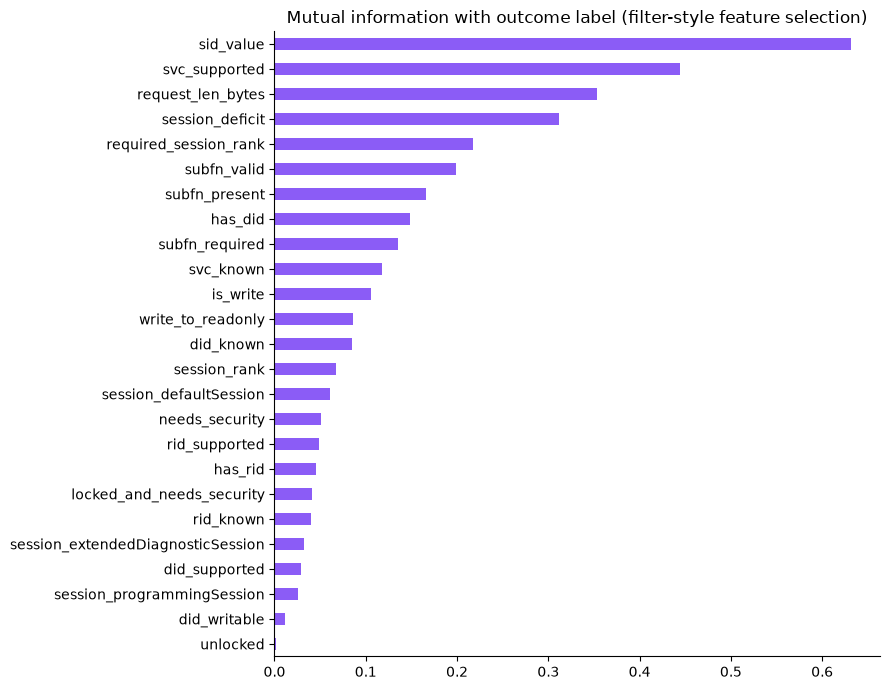

Near-zero MI features (candidates to drop): ['unlocked']


In [15]:
mi = pd.Series(mutual_info_classif(F, outcome_df["label"], discrete_features=True, random_state=SEED),
               index=F.columns).sort_values()
ax = mi.plot(kind="barh", figsize=(9, 7), color="#8b5cf6")
ax.set_title("Mutual information with outcome label (filter-style feature selection)")
plt.tight_layout(); plt.show()
print("Near-zero MI features (candidates to drop):", list(mi[mi < 0.01].index))

## 9. ECU response traces (defect detection)
A golden ECU run (no defects) is the reference. The test run injects 6 defect types at 15%.
Only observable columns (latency, length, NRC, context) are used by the detector; `expected_*` columns are the oracle and are never model inputs.

In [16]:
golden = generate_traces(n=3000, defect_rate=0.0, seed=SEED)
test_tr = generate_traces(n=1000, defect_rate=0.15, seed=SEED + 1)
print("Test-run defect distribution:"); print(test_tr["defect"].value_counts())
print(f"\nDefect rate in test run: {(test_tr.defect != 'none').mean():.1%}")

Test-run defect distribution:
defect
none                   915
latency_violation       27
timeout                 23
unexpected_negative     13
unexpected_positive      9
wrong_nrc                7
truncated_response       6
Name: count, dtype: int64

Defect rate in test run: 8.5%


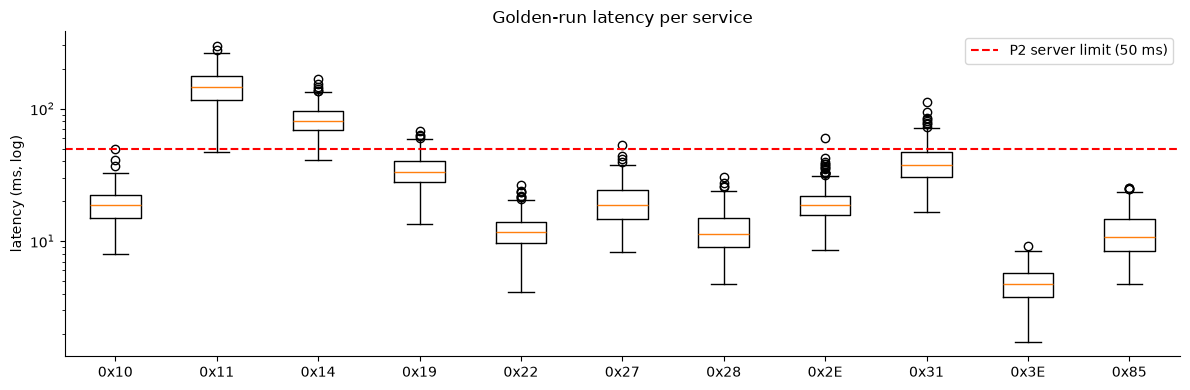

Latency depends strongly on the service -> per-service robust z-score is engineered (TraceFeaturizer).


In [17]:
sids = sorted(BASE_LATENCY_MS)
fig, ax = plt.subplots(figsize=(12, 4))
ax.boxplot([golden.loc[golden.sid == s, "latency_ms"] for s in sids], tick_labels=[f"0x{s:02X}" for s in sids])
ax.axhline(P2_SERVER_MS, color="red", ls="--", label=f"P2 server limit ({P2_SERVER_MS:.0f} ms)")
ax.set_yscale("log"); ax.set_ylabel("latency (ms, log)"); ax.set_title("Golden-run latency per service")
ax.legend(); plt.tight_layout(); plt.show()
print("Latency depends strongly on the service -> per-service robust z-score is engineered (TraceFeaturizer).")

In [18]:
# Univariate IQR outlier rule on latency, per service, fitted on the golden run
lim = golden.groupby("sid")["latency_ms"].quantile([0.25, 0.75]).unstack()
lim["upper"] = lim[0.75] + 1.5 * (lim[0.75] - lim[0.25])
test_tr["iqr_outlier"] = test_tr["latency_ms"] > test_tr["sid"].map(lim["upper"])
tab = pd.crosstab(test_tr["defect"], test_tr["iqr_outlier"], normalize="index").mul(100).round(1)
tab.columns = ["not flagged %", "flagged %"]
print("A univariate IQR rule catches timing defects but is blind to wrong NRCs / truncation ->")
print("motivates the multivariate Isolation Forest (notebook 02) + the engine oracle.")
tab

A univariate IQR rule catches timing defects but is blind to wrong NRCs / truncation ->
motivates the multivariate Isolation Forest (notebook 02) + the engine oracle.


,not flagged %,flagged %
defect,,
latency_violation,0.0,100.0
none,97.7,2.3
timeout,0.0,100.0
truncated_response,100.0,0.0
unexpected_negative,92.3,7.7
unexpected_positive,100.0,0.0
wrong_nrc,100.0,0.0


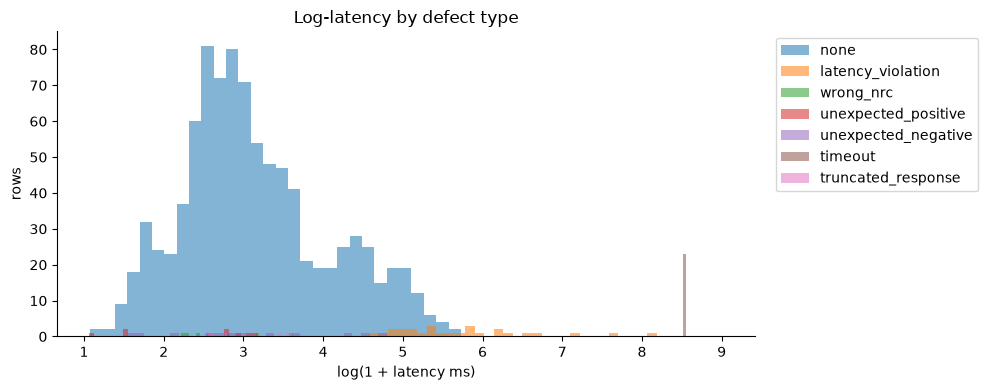

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
for d in test_tr["defect"].unique():
    ax.hist(np.log1p(test_tr.loc[test_tr.defect == d, "latency_ms"]), bins=30, alpha=0.55, label=d)
ax.set_xlabel("log(1 + latency ms)"); ax.set_ylabel("rows"); ax.set_title("Log-latency by defect type")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

## 10. Takeaways that drive modelling choices
1. **Imbalance** (≈9x) → `class_weight="balanced"`, stratified folds, macro-F1 as the headline metric.
2. **Template leakage** → a random split leaks verbatim duplicates. Every intent experiment uses `StratifiedGroupKFold` on `template_id`, and the external hand-written challenge set is never used for training or tuning.
3. **Noise** (typos, abbreviations) → char n-grams + abbreviation expansion, which a keyword matcher lacks.
4. **Tabular redundancy** → correlated one-hots and near-zero-MI features. Selection is evaluated in notebook 02.
5. **Defects** → a univariate rule only sees timing, so a multivariate anomaly detector plus the deterministic oracle are combined.